# RNN 2D
### Il collasso del secondo valore singolare anticipa il collasso della memoria 2D?
### Ora il target contiene 2 numeri, con input sempre scalare.
### Ci sono quindi 2 gdl indipendenti nella rete.

In [5]:
import torch
import torch.nn as nn

torch.manual_seed(42)

hidden_size_2d = 8

class MemoryRNN2D(nn.Module): # Forse soffre di timing bias (a viene valutato prima di b)
    def __init__(self, hidden_size=8):
        super().__init__()

        self.hidden_size = hidden_size
        self.Wx = nn.Linear(1, hidden_size)
        self.Wh = nn.Linear(hidden_size, hidden_size, bias=False)

        self.readout = nn.Linear(hidden_size, 1)

    def forward(self, x):
        batch_size, seq_len, _ = x.shape

        h = torch.zeros(batch_size, self.hidden_size, device=x.device)

        states = []

        for t in range(seq_len):
            h = torch.tanh(self.Wx(x[:, t]) + self.Wh(h))

            states.append(h)

        y_hat = self.readout(h)

        return y_hat, states

In [6]:
model2 = MemoryRNN2D(hidden_size=8)

optimizer2 = torch.optim.Adam(model2.parameters(), lr=0.003)

criterion = nn.MSELoss()

In [20]:
def generate_batch_2d(batch_size=128, seq_len=7):
    x = torch.zeros(batch_size, seq_len, 1)

    a = torch.randint(1, 10, (batch_size,)).float() / 9.0

    b = torch.randint(1, 10, (batch_size,)).float() / 9.0

    # a e b campionati indipendentemente
    x[:, 0, 0] = a
    x[:, 0, 0] = b

    y = torch.stack([a, b], dim=1)

    return x, y

In [8]:
# Training
epochs = 3000

for epoch in range(epochs):
    x_batch, y_batch = generate_batch_2d(batch_size=128, seq_len=7)

    optimizer2.zero_grad()

    pred, _ = model2(x_batch)

    loss = criterion(pred, y_batch)

    loss.backward()

    torch.nn.utils.clip_grad_norm_(model2.parameters(), 1.0)

    optimizer2.step()

    if epoch % 250 == 0:
        print(f"Epoch {epoch:4d} | " f"Loss = {loss.item():.8f}")

Epoch    0 | Loss = 0.38803732
Epoch  250 | Loss = 0.08950730
Epoch  500 | Loss = 0.03563094
Epoch  750 | Loss = 0.03837814
Epoch 1000 | Loss = 0.04386770
Epoch 1250 | Loss = 0.04437855
Epoch 1500 | Loss = 0.04271515
Epoch 1750 | Loss = 0.03269734
Epoch 2000 | Loss = 0.03703627
Epoch 2250 | Loss = 0.04463558
Epoch 2500 | Loss = 0.04230525
Epoch 2750 | Loss = 0.04040152


In [9]:
def evaluate_2d(seq_len, n_batches=100, batch_size=256):
    errors = []
    model2.eval()

    with torch.no_grad():

        for _ in range(n_batches):
            x, y = generate_batch_2d(batch_size=batch_size, seq_len=seq_len)

            pred, _ = model2(x)

            error = torch.abs(pred - y) * 9.0
            errors.append(error)

    errors = torch.cat(errors)

    return(errors[:, 0].mean().item(), errors[:, 1].mean().item(), errors.mean().item())

In [10]:
for T in [7, 16, 32, 64]:
    mae_a, mae_b, mae_total = evaluate_2d(T)
    print(f"T={T:2d} | " f"MAE a={mae_a:.5f} | " f"MAE b={mae_b:.5f} | " f"MAE total={mae_total:.5f}")

T= 7 | MAE a=2.23448 | MAE b=0.03572 | MAE total=1.13510
T=16 | MAE a=2.22118 | MAE b=1.84164 | MAE total=2.03141
T=32 | MAE a=2.23537 | MAE b=1.24750 | MAE total=1.74144
T=64 | MAE a=2.24211 | MAE b=0.63703 | MAE total=1.43957


In [11]:
def make_probe_2d(seq_len=64, a=7.0, b=3.0):
    x = torch.zeros(1, seq_len, 1)

    x[0, 0, 0] = a / 9.0
    x[0, 1, 0] = b / 9.0

    return x

In [12]:
def effective_rank(S):
    p = S / (S.sum() + 1e-12)
    entropy = -torch.sum(p * torch.log(p + 1e-12))

    return torch.exp(entropy)

In [15]:
def cumulative_spectrum_2d(seq_len=64, a=7.0, b=3.0):
    x = make_probe_2d(seq_len, a, b)

    model2.eval()

    with torch.no_grad():
        pred, states = model2(x)

        Wh = model2.Wh.weight
        P = torch.eye(hidden_size_2d)

        rows = []

        # states[0] contiene già il primo input
        # Partiamo dalla transizione h0 -> h1
        for t in range(1, seq_len):
            h_t = states[t][0]
            D_t = torch.diag(1.0 - h_t**2)

            J_t = D_t @ Wh

            P = J_t @ P

            S = torch.linalg.svdvals(P)

            rank_eff = effective_rank(S)

            rows.append({"t": t, "sigma1": S[0].item(), "sigma2": S[1].item(), "sigma_min": S[-1].item(),
                         "rank_eff": rank_eff.item()})
    return rows
        

In [16]:
rows = cumulative_spectrum_2d(seq_len=64)
print("t | sigma1 | sigma2 | rank_eff")

for r in rows:
    if r["t"] in [1, 2, 4, 8, 16, 32, 63]:
        print(f"{r["t"]:2d} | " f"{r["sigma1"]:.6e} | " f"{r["sigma2"]:.6e} | " f"{r["rank_eff"]:.6f}")

t | sigma1 | sigma2 | rank_eff
 1 | 1.044671e+00 | 8.294349e-01 | 5.763299
 2 | 9.049438e-01 | 4.186126e-01 | 4.161050
 4 | 9.184883e-01 | 1.533491e-01 | 2.110802
 8 | 9.927340e-01 | 1.635750e-01 | 1.517149
16 | 8.260731e-01 | 3.305658e-02 | 1.177138
32 | 8.766866e-01 | 2.052095e-03 | 1.016621
63 | 7.706651e-01 | 7.280645e-06 | 1.000120


In [21]:
# Con classe simultanea
class MemoryRNN2D_Simultaneous(nn.Module): # Forse soffre di timing bias (a viene valutato prima di b)
    def __init__(self, hidden_size=8):
        super().__init__()

        self.hidden_size = hidden_size
        self.Wx = nn.Linear(2, hidden_size)
        self.Wh = nn.Linear(hidden_size, hidden_size, bias=False)

        self.readout = nn.Linear(hidden_size, 2)

    def forward(self, x):
        batch_size, seq_len, _ = x.shape

        h = torch.zeros(batch_size, self.hidden_size, device=x.device)

        states = []

        for t in range(seq_len):
            h = torch.tanh(self.Wx(x[:, t]) + self.Wh(h))

            states.append(h)

        y_hat = self.readout(h)

        return y_hat, states

In [22]:
def generate_batch_2d_simultaneous(batch_size=128, seq_len=7):
    x = torch.zeros(batch_size, seq_len, 2)

    a = torch.randint(1, 10, (batch_size,)).float() / 9.0

    b = torch.randint(1, 10, (batch_size,)).float() / 9.0

    # a e b campionati indipendentemente
    x[:, 0, 0] = a
    x[:, 0, 1] = b

    y = torch.stack([a, b], dim=1)

    return x, y

In [25]:
torch.manual_seed(42)

model2s = MemoryRNN2D_Simultaneous(hidden_size=8)

optimizer2s = torch.optim.Adam(model2s.parameters(), lr=0.003)

criterion = nn.MSELoss()

In [26]:
# Training
epochs = 3000

for epoch in range(epochs):
    x_batch, y_batch = generate_batch_2d_simultaneous(batch_size=128, seq_len=7)

    optimizer2s.zero_grad()

    pred, _ = model2s(x_batch)

    loss = criterion(pred, y_batch)

    loss.backward()

    torch.nn.utils.clip_grad_norm_(model2s.parameters(), 1.0)

    optimizer2s.step()

    if epoch % 250 == 0:
        print(f"Epoch {epoch:4d} | " f"Loss = {loss.item():.8f}")

Epoch    0 | Loss = 0.62694323
Epoch  250 | Loss = 0.08804581
Epoch  500 | Loss = 0.00088235
Epoch  750 | Loss = 0.00030874
Epoch 1000 | Loss = 0.00021562
Epoch 1250 | Loss = 0.00018033
Epoch 1500 | Loss = 0.00010187
Epoch 1750 | Loss = 0.00008855
Epoch 2000 | Loss = 0.00007235
Epoch 2250 | Loss = 0.00005249
Epoch 2500 | Loss = 0.00006386
Epoch 2750 | Loss = 0.00004905


In [27]:
def evaluate_2d_simultaneous(seq_len=7, n_batches=100):
    errors = []
    model2s.eval()

    with torch.no_grad():

        for _ in range(n_batches):
            x, y = generate_batch_2d_simultaneous(batch_size=256, seq_len=seq_len)

            pred, _ = model2s(x)

            error = torch.abs(pred - y) * 9.0
            errors.append(error)

    errors = torch.cat(errors)

    return(errors[:, 0].mean().item(), errors[:, 1].mean().item(), errors.mean().item())

In [28]:
for T in [7, 16, 32, 64]:
    mae_a, mae_b, total = (evaluate_2d_simultaneous(T))
    print(f"T={T:2d} | " f"MAE a={mae_a:.5f} | " f"MAE b={mae_b:.5f} | " f"total={total:.5f}")

T= 7 | MAE a=0.03239 | MAE b=0.06841 | total=0.05040
T=16 | MAE a=5.05891 | MAE b=7.58775 | total=6.32333
T=32 | MAE a=6.09696 | MAE b=9.80051 | total=7.94873
T=64 | MAE a=7.69617 | MAE b=7.73173 | total=7.71395


## Ora entrambi i MAE per T = 7 sono bassi ma già a T = 16 si alzano. 
### Quando sigma_2(P_t) collassa, la rete perde la capacità di conservare due coordinate indipendenti.

In [29]:
def cumulative_spectrum_2d_simultaneous(seq_len=64, a=7.0, b=3.0):
    x = torch.zeros(1, seq_len, 2)

    x[0, 0, 0] = a / 9.0
    x[0, 0, 1] = b / 9.0

    model2s.eval()

    with torch.no_grad():
        pred, states = model2s(x)

        Wh = model2s.Wh.weight
        P = torch.eye(hidden_size_2d)

        rows = []

        # states[0] contiene già il primo input
        # Partiamo dalla transizione h0 -> h1
        for t in range(1, seq_len):
            h_t = states[t][0]
            D_t = torch.diag(1.0 - h_t**2)

            J_t = D_t @ Wh

            P = J_t @ P

            S = torch.linalg.svdvals(P)

            rank_eff = effective_rank(S)

            rows.append({"t": t, "sigma1": S[0].item(), "sigma2": S[1].item(), "sigma3": S[2].item(),
                         "rank_eff": rank_eff.item()})
    return rows
        

In [30]:
rows = cumulative_spectrum_2d_simultaneous(seq_len=64, a=7.0, b=3.0)

print("t | sigma1 | sigma2 | sigma3 | rank_eff")

for r in rows:
    if r["t"] in [1, 2, 4, 8, 16, 32, 63]:
        print(f'{r["t"]:2d} | ' f'{r["sigma1"]:.6e} | ' f'{r["sigma2"]:.6e} | ' f'{r["sigma3"]:.6e} | ' f'{r["rank_eff"]:.6f}')

t | sigma1 | sigma2 | sigma3 | rank_eff
 1 | 1.570421e+00 | 1.305350e+00 | 1.014698e+00 | 6.189124
 2 | 1.728986e+00 | 1.208904e+00 | 7.732003e-01 | 4.585432
 4 | 2.218474e+00 | 1.698406e+00 | 4.249464e-01 | 2.905904
 8 | 4.970079e+00 | 1.815029e+00 | 1.921196e-01 | 2.002117
16 | 1.360052e+01 | 2.040970e-01 | 1.739819e-02 | 1.090404
32 | 3.524919e-01 | 5.103029e-05 | 3.841467e-06 | 1.001562
63 | 2.545568e-04 | 3.343482e-11 | 7.972191e-12 | 1.000003


## Ora la Jacobiana input-output misura quanto l'output è legato all'input;
### Idealmente la diagonale (da_hat/da e db_hat/db) dovrebbe attestarsi su 1, mentre il cross-talk (da_hat/db e db_hat/da) piccolo.

In [31]:
def input_output_jacobian(seq_len, a=7.0, b=3.0):
    # coordinate normalizzate
    z = torch.tensor([a / 9.0, b / 9.0], requires_grad=True)

    def f(z):
        first = z.reshape(1, 1, 2)

        if seq_len > 1:
            rest = torch.zeros(1, seq_len - 1, 2)
            x = torch.cat([first, rest], dim=1)
        else:
            x = first
        pred, _ = model2s(x)

        return pred.squeeze(0)

    K = torch.autograd.functional.jacobian(f, z)

    return K.detach()

# Che relazione tra K_T e la RNN?
### Se |det(K_T)| ~= 1 localmente due dimensioni indipendenti sopravvivono, altrimenti da 2D si passa a 1D.
### Se sigma2(K_T) collassa mentre il MAE esplode, allora il fallimento della memoria 2D coincide con la perdita locale di invertibilità del mapping input-output.

In [32]:
for T in [7, 8, 12, 16, 24, 32, 64]:
    K = input_output_jacobian(T, a=7.0, b=3.0)

    S = torch.linalg.svdvals(K)

    det = torch.linalg.det(K)

    print(f"\nT = {T}")
    print(K)
    print(f"sigma1 = {S[0].item():.8f}")
    print(f"sigma2 = {S[1].item():.8f}")
    print(f"det = {det.item():.8e}")


T = 7
tensor([[ 1.0076, -0.0111],
        [-0.0107,  0.9979]])
sigma1 = 1.01467049
sigma2 = 0.99077904
det = 1.00531423e+00

T = 8
tensor([[-0.3831,  0.4846],
        [-1.2353, -0.5782]])
sigma1 = 1.37296200
sigma2 = 0.59737182
det = 8.20168853e-01

T = 12
tensor([[-1.5131, -0.5710],
        [ 1.4556,  0.2762]])
sigma1 = 2.18511581
sigma2 = 0.18914793
det = 4.13310200e-01

T = 16
tensor([[4.1191, 1.0680],
        [0.0172, 0.0907]])
sigma1 = 4.25545168
sigma2 = 0.08352007
det = 3.55415642e-01

T = 24
tensor([[-0.1184, -0.0306],
        [ 0.9510,  0.2406]])
sigma1 = 0.98853976
sigma2 = 0.00066039
det = 6.52787392e-04

T = 32
tensor([[-0.1039, -0.0262],
        [-0.0063, -0.0016]])
sigma1 = 0.10734490
sigma2 = 0.00000351
det = -3.76730753e-07

T = 64
tensor([[ 2.3262e-05,  5.8791e-06],
        [-5.8994e-05, -1.4910e-05]])
sigma1 = 0.00006541
sigma2 = 0.00000000
det = -2.32721455e-16


## Introduciamo anche un termine nella Loss che tenga conto del collasso della seconda direzione,
### L = L_task + lambda*L_memory
### dove L_memory = (sigma_1(K) - 1)^2 + (sigma_2(K) - 1)^2
### con l'obiettivo di ottenere
### (K^T) K ~= I
### Scegliamo quindi una lunghezza casualmente tra [7, ..., 16]
### e aggiungiamo il regularizer:
### L = L_MSE + lambda (|| (K_T^T)K_T - I ||_F)^2

### In sostanza, vogliamo preservare lo spettro di un sottospazio informativo.

In [2]:
# Prova di un modello 4-D
import torch
import torch.nn as nn

hidden_size_4d = 8

class MemoryRNN4D(nn.Module):
    def __init__(self, hidden_size=8):
        super().__init__()
        self.hidden_size = hidden_size

        self.Wx = nn.Linear(4, hidden_size)
        self.Wh = nn.Linear(hidden_size, hidden_size, bias=False)

        self.readout = nn.Linear(hidden_size, 4)

    def forward(self, x):
        batch_size, seq_len, _ = x.shape
        h = torch.zeros(batch_size, self.hidden_size, device=x.device)

        states = []

        for t in range(seq_len):
            h = torch.tanh(self.Wx(x[:, t]) + self.Wh(h))
            states.append(h)

        y_hat = self.readout(h)

        return y_hat, states

In [2]:
model4 = MemoryRNN4D(hidden_size=hidden_size_4d)

optimizer4 = torch.optim.Adam(model4.parameters(), lr=0.003)

criterion = nn.MSELoss()

In [3]:
def generate_batch_4d(batch_size=128, seq_len=7):
    x = torch.zeros(batch_size, seq_len, 4)

    values = torch.randint(1, 10, (batch_size, 4)).float() / 9.0

    x[:, 0, :] = values

    y = values.clone()

    return x, y

In [6]:
epochs = 4000
for epoch in range(epochs):
    x_batch, y_batch = generate_batch_4d(batch_size=128, seq_len=7)

    optimizer4.zero_grad()

    pred, _ = model4(x_batch) 
    loss = criterion(pred, y_batch)

    loss.backward()

    torch.nn.utils.clip_grad_norm_(model4.parameters(), 1.0)

    optimizer4.step()

    if epoch % 250 == 0:
        print(f"Epoch {epoch:4d} | " f"Loss = {loss.item():.8f}")

Epoch    0 | Loss = 0.63450199
Epoch  250 | Loss = 0.07940573
Epoch  500 | Loss = 0.05861041
Epoch  750 | Loss = 0.04519739
Epoch 1000 | Loss = 0.00213201
Epoch 1250 | Loss = 0.00133048
Epoch 1500 | Loss = 0.00071303
Epoch 1750 | Loss = 0.00054768
Epoch 2000 | Loss = 0.00038154
Epoch 2250 | Loss = 0.00028443
Epoch 2500 | Loss = 0.00025531
Epoch 2750 | Loss = 0.00021189
Epoch 3000 | Loss = 0.00028101
Epoch 3250 | Loss = 0.00024522
Epoch 3500 | Loss = 0.00017189
Epoch 3750 | Loss = 0.00013104


In [7]:
# MAE per coordinata
def evaluate_4d(seq_len, n_batches=100, batch_size=256):
    all_errors = []

    model4.eval()

    with torch.no_grad():
        for _ in range(n_batches):
            x, y = generate_batch_4d(batch_size=batch_size, seq_len=seq_len)

            pred, _ = model4(x)

            error = torch.abs(pred - y) * 9.0
            all_errors.append(error)

    errors = torch.cat(all_errors)
    per_dim = errors.mean(dim=0)

    return(per_dim.tolist(), errors.mean().item())

In [8]:
for T in [7, 8, 12, 16, 24, 32, 64]:
    per_dim, total = evaluate_4d(T)

    print(f"T={T:2d} | " f"MAE dims = " f"{[round(v, 4) for v in per_dim]} | " f"total={total:.4f}") Ge

T= 7 | MAE dims = [0.0772, 0.0901, 0.0718, 0.0683] | total=0.0768
T= 8 | MAE dims = [4.3245, 1.1142, 3.1397, 4.7634] | total=3.3355
T=12 | MAE dims = [3.2798, 8.8936, 4.3895, 4.2863] | total=5.2123
T=16 | MAE dims = [5.5476, 9.9494, 5.9458, 3.0906] | total=6.1334
T=24 | MAE dims = [8.0024, 2.4357, 5.1803, 9.1031] | total=6.1804
T=32 | MAE dims = [6.2128, 7.5968, 5.2392, 5.76] | total=6.2022
T=64 | MAE dims = [6.7996, 5.3973, 3.5666, 8.2746] | total=6.0095


In [9]:
# Generalizzazione Jacobiana K_T = dy_hat/dx_0
def input_output_jacobian_4d(seq_len, values=(7.0, 3.0, 5.0, 2.0)):

    z = torch.tensor([v / 9.0 for v in values], requires_grad=True)

    def f(z):
        first = z.reshape(1, 1, 4)
        if seq_len > 1:
            rest = torch.zeros(1, seq_len - 1, 4)
            x = torch.cat([first, rest], dim=1)

        else:
            x = first

        pred, _ = model4(x)

        return pred.squeeze(0)

    K = torch.autograd.functional.jacobian(f, z)

    return K.detach()

In [11]:
def effective_rank_from_singular_values(S):
    p = S / (S.sum() + 1e-12)

    entropy = -torch.sum(p * torch.log(p + 1e-12))

    return torch.exp(entropy)

In [12]:
for T in [7, 8, 12, 16, 24, 32, 64]:
    K = input_output_jacobian_4d(T)
    S = torch.linalg.svdvals(K)
    det = torch.linalg.det(K)
    rank_eff = effective_rank_from_singular_values(S)

    print(f"\nT={T}")
    print(K)
    print("singular values =", [round(v.item(), 8) for v in S])
    print("effective rank =", rank_eff.item())
    print("det =", f"{det.item():.8e}")


T=7
tensor([[ 9.8517e-01,  1.1518e-02, -6.7449e-03,  2.9563e-02],
        [ 2.4419e-02,  1.0160e+00, -1.4840e-02, -1.8322e-02],
        [-4.9967e-04, -9.3984e-03,  1.0381e+00,  1.4868e-02],
        [ 3.0682e-02,  9.2115e-03,  1.1080e-02,  9.8746e-01]])
singular values = [1.04693401, 1.02568007, 1.00293148, 0.95134968]
effective rank = 3.9974887371063232
det = 1.02457285e+00

T=8
tensor([[-0.6171,  0.5749,  1.0205, -0.3083],
        [-0.0148,  1.0947, -0.4358, -0.2412],
        [ 0.5018,  0.3187,  0.3078,  0.2404],
        [ 0.5909,  0.0492,  0.3336, -0.9860]])
singular values = [1.47452593, 1.14941359, 1.13276029, 0.67600429]
effective rank = 3.8635270595550537
det = 1.29782546e+00

T=12
tensor([[ 0.0456,  0.3688, -0.3431, -1.1043],
        [ 0.1474,  0.0779, -0.6470, -0.1269],
        [-0.4977,  1.0885, -0.6048,  0.2964],
        [ 1.3711,  0.0616, -1.5158,  0.3901]])
singular values = [2.18215895, 1.40229213, 1.17369235, 0.22675338]
effective rank = 3.318474531173706
det = 8.1439149

ValueError: x and y must have same first dimension, but have shapes (1,) and (4,)

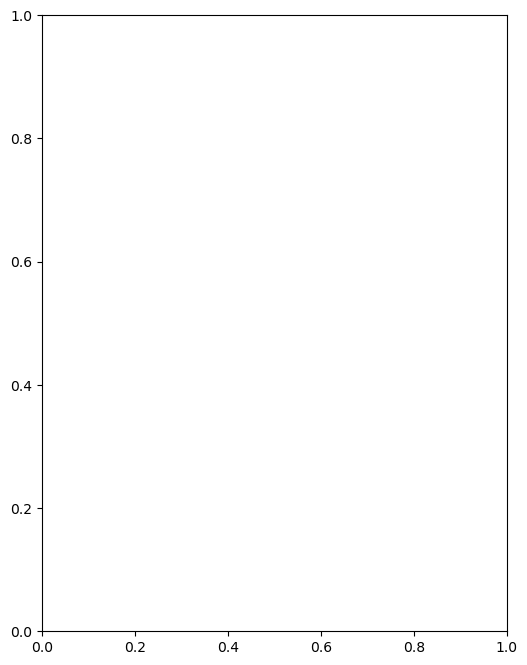

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,8))
K = input_output_jacobian_4d(T)
S = torch.linalg.svdvals(K)

plt.plot(T, [round(v.item(), 8) for v in S])
plt.xlabel("T")
plt.ylabel("singular_values, rank_eff")
plt.title("Singular values and rank_eff of K")

plt.xticks(range(4))
plt.yticks(range(4))

plt.show()

## ISOMETRY ERROR
### E_iso = ||K_T^TK_T - I||_F
### Se E_value >> 0, ||K - I||_F >> 0, ma rank ~= 4, allora il primo problema è la deriva della mappa.
### Quando sigma_min -> 0, allora si aggiunge la perdita irreversibile locale di gdl.

In [18]:
def memory_diagnostics_4d(seq_len, values=(7.0, 3.0, 5.0, 2.0)):
    z = torch.tensor([v / 9.0 for v in values], requires_grad=True)

    def f(z):
        first = z.reshape(1, 1, 4)
        if seq_len > 1:
            rest = torch.zeros(1, seq_len - 1, 4)
            x = torch.cat([first, rest], dim=1)
        else:
            x = first

        pred, _ = model4(x)

        return pred.squeeze(0)

    y = f(z)

    K = torch.autograd.functional.jacobian(f, z)
    I = torch.eye(4)

    # Prediction/value error
    value_error = torch.linalg.vector_norm(y.detach() - z.detach())

    # Is the Jacobian actually close to I?
    jacobian_error = torch.linalg.matrix_norm(K.detach() - I, ord="fro")

    # Does it at least preserve geometry?
    isometry_error = torch.linalg.matrix_norm(K.detach().T @ K.detach() - I, ord="fro")

    S = torch.linalg.svdvals(K.detach())

    return {"value_error": value_error.item(), "jacobian_error": jacobian_error.item(), "isometry_error": isometry_error.item(),
        "sigma_min": S[-1].item(), "sigma_max": S[0].item()}

In [20]:
print("T | value_err | ||K-I|| | ||K^TK - I|| | sigma_min | sigma_max")
for T in [7, 8, 12, 16, 24, 32, 64]:
    d = memory_diagnostics_4d(T)

    print(f"{T:2d} | " f'{d["value_error"]:.5f} | ' f'{d["jacobian_error"]:.5f} | ' f'{d["isometry_error"]:.5f} | '
        f'{d["sigma_min"]:.6f} | ' f'{d["sigma_max"]:.6f}')

T | value_err | ||K-I|| | ||K^TK - I|| | sigma_min | sigma_max
 7 | 0.02051 | 0.07579 | 0.14485 | 0.951350 | 1.046934
 8 | 0.82669 | 3.10428 | 1.36271 | 0.676004 | 1.474526
12 | 0.99705 | 3.51275 | 4.01592 | 0.226753 | 2.182159
16 | 1.57443 | 3.11906 | 7.08316 | 0.267383 | 2.789459
24 | 1.68356 | 5.69060 | 17.48054 | 0.079926 | 4.291551
32 | 1.32645 | 4.38367 | 19.08798 | 0.004257 | 4.476590
64 | 1.22388 | 4.95691 | 26.14112 | 0.000000 | 5.205151


### Siccome il r_eff a T=8 è ancora alto (3.86) e anche sigma_min vicino a 1 (0.68), si ha
### temporal-map drift/distortion precede dimension collapse

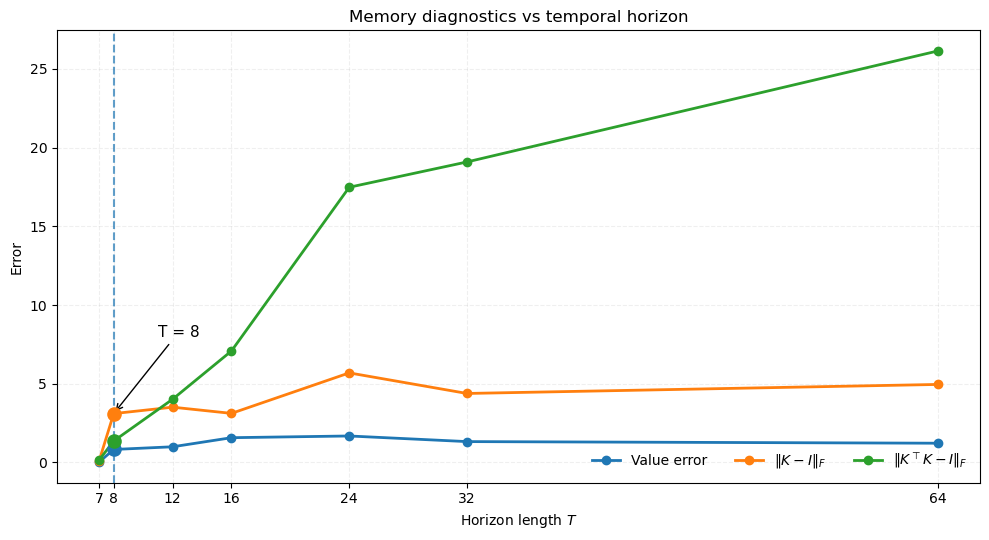

In [29]:
import matplotlib.pyplot as plt
import numpy as np

#fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
fig, ax = plt.subplots(figsize=(10, 5.5))

# Ricostruiamo il dict d:
diagnostics = []
T_values = np.array([7, 8, 12, 16, 24, 32, 64])

for T in T_values:
    d = memory_diagnostics_4d(T)
    diagnostics.append(d)

value_error = np.array([d["value_error"] for d in diagnostics])
jacobian_error = np.array([d["jacobian_error"] for d in diagnostics])
isometry_error = np.array([d["isometry_error"] for d in diagnostics])
sigma_min = np.array([d["sigma_min"] for d in diagnostics])
sigma_max = np.array([d["sigma_max"] for d in diagnostics])

ax.plot(T_values, value_error, "o-", linewidth=2, label="Value error")
ax.plot(T_values, jacobian_error, "o-", linewidth=2, label=r"$\|K-I\|_F$")
ax.plot(T_values, isometry_error, "o-", linewidth=2, label=r"$\|K^\top K-I\|_F$")

# Highlight T = 8
selected_T = 8
idx = np.where(T_values == selected_T)[0][0]
ax.axvline(selected_T, linestyle="--", linewidth=1.5, alpha=0.7)

for y in [value_error[idx], jacobian_error[idx], isometry_error[idx]]:
    ax.scatter(selected_T, y, s=90,zorder=5)

ax.annotate("T = 8", xy=(8, jacobian_error[idx]), xytext=(11, 8), arrowprops=dict(arrowstyle="->"), fontsize=11)

ax.set(xlabel="Horizon length $T$", ylabel="Error", title="Memory diagnostics vs temporal horizon")
ax.set_xticks(T_values)
ax.grid(alpha=.2, linestyle="--")
ax.legend(frameon=False, ncols=3)

plt.tight_layout()
plt.show()

# Esperimento A: persistent readout
### Facciamo produrre alla stessa hidden trajectory un output a ogni timestep e continui a rappresentare lo stesso vettore
### L_persistent = 1/T * sums_t(1,T)||y_hat_t - y||^2
#### Quindi y_hat_1 ~= ... ~= y_hat_7

### Questo per capire se il problema era l'obiettivo di training, premiante una soluzione temporale (se per T = 8 MAE -> 0) o
### il vanishing gradient o il rank (per T = 8, MAE 3 o oltre)

In [9]:
torch.manual_seed(42)

model4_persistent = MemoryRNN4D(hidden_size=8)
optimizer4_persistent = torch.optim.Adam(model4_persistent.parameters(), lr=0.003)

In [31]:
# Train
for epoch in range(4000):
    x_batch, y_batch = generate_batch_4d(batch_size=128, seq_len=7)
    optimizer4_persistent.zero_grad()

    pred, states = model4_persistent(x_batch)
    loss = 0.0

    for h_t in states:
        y_t = model4_persistent.readout(h_t)
        loss = loss + criterion(y_t, y_batch)

    loss = loss / len(states)

    loss.backward()

    torch.nn.utils.clip_grad_norm_(model4_persistent.parameters(), 1.0)

    optimizer4_persistent.step()

    if epoch % 250 == 0:
        print(f"Epoch {epoch:4d} | " f"Loss={loss.item():.8f}")

Epoch    0 | Loss=0.71002865
Epoch  250 | Loss=0.07565523
Epoch  500 | Loss=0.03621960
Epoch  750 | Loss=0.02162972
Epoch 1000 | Loss=0.00209950
Epoch 1250 | Loss=0.00140835
Epoch 1500 | Loss=0.00111452
Epoch 1750 | Loss=0.00071616
Epoch 2000 | Loss=0.00063511
Epoch 2250 | Loss=0.00047760
Epoch 2500 | Loss=0.00036213
Epoch 2750 | Loss=0.00037305
Epoch 3000 | Loss=0.00032456
Epoch 3250 | Loss=0.00024593
Epoch 3500 | Loss=0.00019902
Epoch 3750 | Loss=0.00018744


In [32]:
def evaluate_model_4d(model, seq_len, n_batches=100, batch_size=256):
    errors = []
    model.eval()

    with torch.no_grad():
        for _ in range(n_batches):
            x, y = generate_batch_4d(batch_size=batch_size, seq_len=seq_len)

            pred, _ = model(x)
            error = torch.abs(pred - y) * 9.0
            errors.append(error)

    errors = torch.cat(errors)

    return(errors.mean(dim=0).tolist(), errors.mean().item())

In [33]:
print("T | baseline | persistent")
for T in [7, 8, 12, 16, 24, 32, 64]:
    _, base = evaluate_model_4d(model4, T)
    _, persistent = evaluate_model_4d(model4_persistent, T)

    print(f"{T:2d} | " f"{base:.5f} | " f"{persistent:.5f}")

T | baseline | persistent
 7 | 0.07648 | 0.13606
 8 | 3.33294 | 0.15566
12 | 5.19427 | 0.23506
16 | 6.09722 | 0.31284
24 | 6.19067 | 0.46581
32 | 6.18780 | 0.61606
64 | 6.01436 | 1.15838


## Problema
### La persistent loss ha creato una memoria quasi-stazionaria (||h_t+1 - h_t|| ~= 0) o uno stato che continua a muoversi ?

In [7]:
def state_and_output_drift(model, seq_len=64, values=(7.0, 3.0, 5.0, 2.0)):
    x = torch.zeros(1, seq_len, 4)
    x[0, 0] = torch.tensor(values) / 9.0
    model.eval()

    with torch.no_grad():
        _, states = model(x)
        rows = []

        for t in range(len(states) - 1):
            h_t = states[t]
            h_next = states[t + 1]
            state_drift = torch.linalg.vector_norm(h_next - h_t).item()
            y_t = model.readout(h_t)
            y_next = model.readout(h_next)
            output_drift = torch.linalg.vector_norm(y_next - y_t).item()
            rows.append((t, state_drift, output_drift))

    return rows

In [14]:
base_drift = state_and_output_drift(model4, seq_len=64)
persistent_drift = state_and_output_drift(model4_persistent, seq_len=64)

print("t | base_h | persistent_h | base_y | persistent_y")

for t in [0, 1, 2, 4, 8, 16, 32, 62]:
    b = base_drift[t]
    p = persistent_drift[t]

    print(f"{t:2d} | " f"{b[1]:.6f} | " f"{p[1]:.6f} | " f"{b[2]:.6f} | " f"{p[2]:.6f}")

t | base_h | persistent_h | base_y | persistent_y
 0 | 0.735561 | 1.033868 | 0.195320 | 0.621313
 1 | 0.322216 | 0.733722 | 0.132700 | 0.512055
 2 | 0.163460 | 0.553986 | 0.064144 | 0.403402
 4 | 0.016069 | 0.240610 | 0.007112 | 0.171410
 8 | 0.000595 | 0.016709 | 0.000169 | 0.010468
16 | 0.000003 | 0.000107 | 0.000001 | 0.000073
32 | 0.000000 | 0.000000 | 0.000000 | 0.000000
62 | 0.000000 | 0.000000 | 0.000000 | 0.000000


## Q_t = ||R(h_t+1) - R(h_t)||/(||h_t+1 - h_t|| + epsilon)
### Quanto movimento nello hidden state diventa effettivamente movimento nell'output?

In [12]:
def drift_visibility(rows):
    result = []
    for t, h_drift, y_drift in rows:
        q = y_drift / (h_drift + 1e-12)
        result.append((t, q))

    return result

In [15]:
persistent_visibility = drift_visibility(persistent_drift)

print("t | output-visible fraction")
for t, q in persistent_visibility:
    if t in [0, 1, 2, 4, 8, 16, 32, 62]:
        print(f"{t:2d} | {q:.8f}")

t | output-visible fraction
 0 | 0.60095973
 1 | 0.69788720
 2 | 0.72818092
 4 | 0.71239662
 8 | 0.62647192
16 | 0.68481388
32 | 0.49998814
62 | 0.55467955


## Si ha
### delta_y_t = W_out*delta_h_t
### Se delta_h_t è quasi nel null space di W_out, allora
### W_out*delta_h_t ~= 0

#### Ovvero la hidden state evolve, ma lungo direzioni che non alterano la memoria leggibile.
#### Quindi sarebbe un indizio di separazione spontanea tra memory subspace e latent dynamic subspace.

In [16]:
# Quanto cade il drift nel null space?
Wout = model4_persistent.readout.weight.detach()

U, S, Vh = torch.linalg.svd(Wout, full_matrices=True)

print("Readout singular values:")
print(S)

Readout singular values:
tensor([0.8553, 0.6311, 0.5097, 0.2696])


In [17]:
null_basis = Vh[4:, :]

print("Null-space basis shape:", null_basis.shape)

Null-space basis shape: torch.Size([4, 8])


In [18]:
# Proiettiamo nel null space ogni movimento dello stato
def nullspace_drift_fraction(model, seq_len=64, values=(7.0, 3.0, 5.0, 2.0)):
    x = torch.zeros(1, seq_len, 4)
    x[0, 0] = torch.tensor(values) / 9.0
    model.eval()

    with torch.no_grad():
        _, states = model(x)
        Wout = model.readout.weight

        _, _, Vh = torch.linalg.svd(Wout, full_matrices=True)

        null_basis = Vh[4:, :]

        rows = []

        for t in range(len(states) - 1):
            delta_h = (states[t + 1][0] - states[t][0])
            coeffs = null_basis @ delta_h
            null_component = (null_basis.T @ coeffs)
            frac = (torch.linalg.vector_norm(null_component) / (torch.linalg.vector_norm(delta_h) + 1e-12))

            rows.append((t, frac.item()))

    return rows

In [19]:
null_fractions = nullspace_drift_fraction(model4_persistent)

print("t | null-space fraction")

for t, frac in null_fractions:
    if t in [0, 1, 2, 4, 8, 16, 32, 62]:
        print(f"{t:2d} | {frac:.8f}")

t | null-space fraction
 0 | 0.47027206
 1 | 0.24266455
 2 | 0.37613624
 4 | 0.47697678
 8 | 0.64491373
16 | 0.54552221
32 | 0.63409388
62 | 0.54560018


## Se
### ||h_t+1 - h_t|| > 0 e Q_t << 1 e contemporaneamente null-space fraction ~= 1
### La rete continua a evolvere, tutto il movimento avviene approssimat. nel null space del readout
#### Quindi h_t = m_t + d_t,
#### m_t in M sottospazio leggibile/persistente e
#### d_t in ker(R) sottospazio dinamico.

### Si ha che ||h_t+1 - h_t|| -> 0
### h_t -> h_star e R(h_t) -> R(h_star), inoltre
### ||products_kerR(delta_h_t)||/||delta_h_t|| != 1, non converge a 1. Anche output-visible fraction si attesta su 0.6-0.7
## Può essere che siccome anche a T=64 la persistent ha MAE ~= 1.16,
### h_star = h_star(a, b, c, d)
### ovvero input diversi convergono verso punti diversi hidden.

#### Per avere manifold continua di punti fissi ci aspettiamo 
###  .)direzioni TANGENTI alla memory manifold (Jv_i ~= v_i)
###  ..)direzioni ORTOGONALI alla memory manifold ( Jv_j = lambda_j*v_j), |lambda_j| < 1.
### In una base ideale, J ~ (I_4  0)
###                         (0    A), rho(A) < 1.

## Per input nullo:
### F(h) = tanh(W_h*h + b_x)
### J_star = diag(1 - h_star^2)W_h.

In [20]:
def fixed_point_spectrum(model, values=(7.0, 3.0, 5.0, 2.0), seq_len=128):
    x = torch.zeros(1, seq_len, 4)
    x[0, 0] = torch.tensor(values) / 9.0
    model.eval()

    with torch.no_grad():
        _, states = model(x)
        h_star = states[-1][0]
        Wh = model.Wh.weight

        D = torch.diag(1.0 - h_star**2)
        J = D @ Wh

        eigvals = torch.linalg.eigvals(J)
        S = torch.linalg.svdvals(J)

    return h_star, J, eigvals, S

In [21]:
h_star, J_star, eigvals, S = (fixed_point_spectrum(model4_persistent))

print("Eigenvalues:")
for i, ev in enumerate(eigvals):
    print(i, ev.item(), "|lambda| =", abs(ev.item()))

print("\nSingular values:")
print(S)

Eigenvalues:
0 (-0.49584081768989563+0.1602812260389328j) |lambda| = 0.5211028573208247
1 (-0.49584081768989563-0.1602812260389328j) |lambda| = 0.5211028573208247
2 (-0.31432801485061646+0j) |lambda| = 0.31432801485061646
3 (-0.04062548652291298+0.28671780228614807j) |lambda| = 0.28958164358781807
4 (-0.04062548652291298-0.28671780228614807j) |lambda| = 0.28958164358781807
5 (0.29419398307800293+0j) |lambda| = 0.29419398307800293
6 (0.10006128251552582+0.09477217495441437j) |lambda| = 0.13781881368028823
7 (0.10006128251552582-0.09477217495441437j) |lambda| = 0.13781881368028823

Singular values:
tensor([1.0767, 0.7983, 0.6481, 0.4114, 0.2993, 0.1954, 0.1498, 0.0199])


## C'è bisogno della Jacobiana di encoding:
### E = dh/d(a,b,c,d) in R^(8x4)
### Colonne: 4 dir hidden in cui si codificano le 4 coordinate della memoria
### J_star * E ~= E?
#### Ovvero le direzioni contenenti informazione vengono lasciate quasi invarianti dalla dinamica?

### eps_mem = ||J_star * E - E||_F / ||E||_F

## Lasciamo evolvere la rete per 128 timestep


In [22]:
def final_state_for_values(values, seq_len=128):
    x = torch.zeros(1, seq_len, 4)
    x[0, 0] = (torch.tensor(values) / 9.0)

    model4_persistent.eval()

    with torch.no_grad():

        pred, states = model4_persistent(x)

    return(states[-1][0].clone(), pred[0].clone())

In [23]:
test_memories = [
    (1, 1, 1, 1),
    (9, 9, 9, 9),
    (1, 9, 1, 9),
    (9, 1, 9, 1),
    (2, 4, 6, 8), 
    (8, 6, 4, 2),
]

final_states = []

for values in test_memories:
    h_star, pred = final_state_for_values(values)

    final_states.append(h_star)

    print(values, "-> prediction:", (pred * 9).numpy())

print("\nPairwise final-state distances:")

for i in range(len(final_states)):
    for j in range(i + 1, len(final_states)):
        d = torch.linalg.vector_norm(final_states[i] - final_states[j])

        print(test_memories[i], " vs ", test_memories[j], " = ", d.item())

(1, 1, 1, 1) -> prediction: [-3.4526193  -3.5660338  -0.36474675 -0.25075683]
(9, 9, 9, 9) -> prediction: [-3.4526193  -3.5660338  -0.36474675 -0.25075683]
(1, 9, 1, 9) -> prediction: [-3.4526193  -3.5660338  -0.3647469  -0.25075683]
(9, 1, 9, 1) -> prediction: [-3.4526193  -3.5660338  -0.3647469  -0.25075683]
(2, 4, 6, 8) -> prediction: [-3.4526193  -3.5660338  -0.3647469  -0.25075683]
(8, 6, 4, 2) -> prediction: [-3.4526193  -3.5660338  -0.3647469  -0.25075683]

Pairwise final-state distances:
(1, 1, 1, 1)  vs  (9, 9, 9, 9)  =  0.0
(1, 1, 1, 1)  vs  (1, 9, 1, 9)  =  2.686345013103164e-08
(1, 1, 1, 1)  vs  (9, 1, 9, 1)  =  2.686345013103164e-08
(1, 1, 1, 1)  vs  (2, 4, 6, 8)  =  2.686345013103164e-08
(1, 1, 1, 1)  vs  (8, 6, 4, 2)  =  2.686345013103164e-08
(9, 9, 9, 9)  vs  (1, 9, 1, 9)  =  2.686345013103164e-08
(9, 9, 9, 9)  vs  (9, 1, 9, 1)  =  2.686345013103164e-08
(9, 9, 9, 9)  vs  (2, 4, 6, 8)  =  2.686345013103164e-08
(9, 9, 9, 9)  vs  (8, 6, 4, 2)  =  2.686345013103164e-08
(1, 

In [24]:
nearby_memories = [
    (7.0, 3.0, 5.0, 2.0),
    (7.01, 3.0, 5.0, 2.0),
    (7.1, 3.0, 5.0, 2.0),
    (8.0, 3.0, 5.0, 2.0),
]

nearby_states = []

for values in nearby_memories:
    h_star, pred = final_state_for_values(values, seq_len=256)

    nearby_states.append(h_star)

    print(values, "->", (pred * 9).numpy())

(7.0, 3.0, 5.0, 2.0) -> [-3.4526193  -3.5660338  -0.3647469  -0.25075683]
(7.01, 3.0, 5.0, 2.0) -> [-3.4526193  -3.5660338  -0.3647469  -0.25075683]
(7.1, 3.0, 5.0, 2.0) -> [-3.4526193  -3.5660338  -0.3647469  -0.25075683]
(8.0, 3.0, 5.0, 2.0) -> [-3.4526193  -3.5660338  -0.3647469  -0.25075683]


### Per la model4_persistent quindi il meccanismo non è input diverso -> attrattore diverso ma
### input diverso -> transiente informativo lungo -> unico attrattore finale

#### Abbiamo fin qui costruito un slow transient memory, più che una memoria persistente.
### L'informazione utile però non deve venire attirata verso l'unico attrattore..
### Meglio avere J_t * v ~= v, ||P_t * v|| ~= 1 per lunghi timeline.
### Regularizer: comportamento ideale: K_T ~= I_4.
### Penalizzazione: L_J = ||K_T - I||_F^2.
#### L = L_persistent + lambda_J * L_j
#### L_persistent: "Mantieni corretto il valore"
#### L_J: "Mantieni corretta anche la mappatura locale delle variazioni"

In [ ]:
import torch

torch.manual_seed(42)
model4_jac = MemoryRNN4D(hidden_size=8)
optimizer4_jac = torch.optim.Adam(model4_jac.parameters(), lr=0.001)

def jacobian_memory_loss(model, z, seq_len):
    # z shape: [4]
    z = z.requires_grad_(True)

    def f(z_local):
        first = z_local.reshape(1, 1, 4)
        rest = torch.zeros(1, seq_len - 1, 4)
        x = torch.cat([first, rest], dim=1)

        pred, _ = model(x)

        return pred.squeeze(0)

    K = torch.autograd.functional.jacobian(f, z, create_graph=True) # Per fare backprop attraverso la jacobiana imponiamo create_graph=True

    I = torch.eye(4, device=z.device)

    return ((K - I) ** 2).mean()

In [6]:
log_file = "jacobian_diagnostics_3.txt"

with open(log_file, "w") as f:
    f.write("JACOBIAN MEMORY EXPERIMENT TIME-HORIZON\n")
    f.write("=" * 70 + "\n\n")

In [7]:
# Training con orizzonte variabile MULTI
lambda_jac = 0.1
for step in range(3000):
    T = torch.randint(low=7, high=33, size=(1,)).item()

    values = torch.randint(1, 10, (4,)).float() / 9.0

    x = torch.zeros(1, T, 4)
    x[0, 0] = values

    optimizer4_jac.zero_grad()

    pred, states = model4_jac(x)

    # persistent value loss
    value_loss = 0.0
    for h_t in states:
        y_t = model4_jac.readout(h_t)
        value_loss = value_loss + ((y_t.squeeze(0) - values) ** 2).mean()
    #jac_loss = jacobian_memory_loss(model4_jac, values.clone(), T)
    # LOSS MULTI variabile, con L_J^(multi) = sums_(t in H)(||K_T - I_4||_F^2 / (4 * |H|))
    jac_loss = multi_horizon_jacobian_loss(model4_jac, values.clone(), T)
    
    loss = (value_loss + lambda_jac * jac_loss)
    loss.backward()

    if step % 250 == 0:
        # ---- Jacobian K_test ----
        z_test = values.detach().clone().requires_grad_(True)

        def f_test(z):
            first = z.reshape(1, 1, 4)
            rest = torch.zeros(1, T - 1, 4)

            x_test = torch.cat([first, rest], dim=1)
            pred_test, _ = model4_jac(x_test)
            return pred_test.squeeze(0)

        K_test = torch.autograd.functional.jacobian(
            f_test, z_test
        )

        singular_values = torch.linalg.svdvals(K_test.detach())

        # ---- Gradiente della Jacobian loss ----
        # La ricalcoliamo perchè il graph precedente è già stato usato da loss.backward()
        jac_check = jacobian_memory_loss(model4_jac, values.detach().clone(), T)

        grads_J = torch.autograd.grad(jac_check, tuple(model4_jac.parameters()), allow_unused=True)

        # ---- Scrittura TXT ----
        with open(log_file, "a") as f:
            f.write(f"STEP {step} | T = {T}\n")
            f.write(f"value_loss = {value_loss.item():.8f}\n")
            f.write(f"jac_loss = {jac_loss.item():.8f}\n")
            f.write(f"total_loss = {loss.item():.8f}\n")
            f.write("K_test:\n")
            f.write(str(K_test.detach().cpu().numpy()))
            f.write("\n\n")
            f.write("Singular values:\n")
            f.write(str(singular_values.cpu().numpy()))
            f.write("\n\n")
            f.write("Jacobian-loss gradient norms:\n")
            for (name, p), g in zip(model4_jac.named_parameters(), grads_J):
                if g is None:
                    f.write(f"{name}: NONE\n")
                else:
                    norm = torch.linalg.vector_norm(g.detach()).item()
                    f.write(f"{name}: {norm:.12e}\n")
            f.write("\n" + "=" * 70 + "\n\n")

            # Sul notebook solo una riga
            print(f"step={step:4d} | " f"value={value_loss.item():.5f} | " f"jac={jac_loss.item():.5f} | "
                  f"sigma={singular_values.detach().cpu().numpy()} | " f"total={loss.item():.5f}")

    torch.nn.utils.clip_grad_norm_(model4_jac.parameters(), 1.0)

    optimizer4_jac.step()
    

NameError: name 'multi_horizon_jacobian_loss' is not defined

# Vogliamo introdurre una Selctive Dynamical Memory
## La rete può imparare la costruzione di un sottospazio informativo Mt a ogni passo?

### J_t * v ~= v, v in M_t (ricorda)
### J_t * v ~= lambda * v, |lambda| < 1, v in F_t (dimentica)
### J_t * v ~= A * v, v in C_t (elabora)

#### Il problema dell'attribuzione dell'errore può essere quindi affrontato costruendo una diagnostica dinamica che chieda:
#### Quale trasformazione lungo la traiettoria ha distrutto l'informazione necessaria?

A T=31, step 250, per esempio:

∥∇
W
h
	​

	​

L
J
	​

∥≈1.06×10
−11
.

Quando invece capita T=7, a step 1000, la Jacobiana è ancora piccola ma molto più viva e:

∥∇
W
h
	​

	​

L
J
	​

∥≈3.9×10
−3
.

Quindi succede qualcosa di concettualmente molto interessante:

il regularizer progettato per salvare il credit transport soffre esso stesso di un problema di temporal credit transport.
	​


Matematicamente:

∇
θ
	​

L
J
	​

=
∂K
∂L
J
	​

	​

∂θ
∂K
	​

.

Quando K≈0,

∂K
∂L
J
	​

	​


non è zero: la loss sa benissimo che vorrebbe K=I.

Il problema è il secondo fattore:

∂θ
∂K
	​

≈0.
	​


Cioè il segnale di secondo ordine che dovrebbe dire ai parametri come ripristinare la Jacobiana è ormai svanito lungo la catena temporale.

Usiamo Jacobiane a più orizzonti:

L
J
multi
	​

=
∣H∣
1
	​

t∈H
∑
	​

4
∥K
t
	​

−I∥
F
2
	​

	​

	​


con, per esempio,

H={2,4,8,T}.

Così se K
24
	​

 è già morto, magari:

K
2
	​

,K
4
	​

,K
8
	​


sono ancora vivi e possono fornire un gradiente utile ai parametri.

### Quindi, vincoli Jacobiani intermedi possono impedire il collasso del canale informativo prima della correzione

In [12]:
def multi_horizon_jacobian_loss(model, z, T):

    horizons = sorted(set([
        min(2, T),
        min(4, T),
        min(8, T),
        T
    ]))

    losses = []

    for H in horizons:

        z_h = z.clone().requires_grad_(True)

        def f(z_local):

            first = z_local.reshape(1, 1, 4)

            if H > 1:
                rest = torch.zeros(
                    1, H - 1, 4
                )

                x = torch.cat(
                    [first, rest],
                    dim=1
                )
            else:
                x = first

            pred, _ = model(x)

            return pred.squeeze(0)

        K = torch.autograd.functional.jacobian(
            f,
            z_h,
            create_graph=True
        )

        I = torch.eye(4)

        # normalizzazione:
        # K=0 -> loss=1 invece di 0.25
        L_h = torch.sum(
            (K - I) ** 2
        ) / 4.0

        losses.append(L_h)

    return torch.stack(losses).mean()

In [8]:
def horizon_jacobian_diagnostics(model, values, T):

    horizons = sorted(set([
        min(2, T),
        min(4, T),
        min(8, T),
        T
    ]))

    results = {}

    for H in horizons:

        z = values.detach().clone().requires_grad_(True)

        def f(z_local):

            first = z_local.reshape(1, 1, 4)

            if H > 1:
                rest = torch.zeros(
                    1,
                    H - 1,
                    4
                )

                x = torch.cat(
                    [first, rest],
                    dim=1
                )
            else:
                x = first

            pred, _ = model(x)

            return pred.squeeze(0)

        K = torch.autograd.functional.jacobian(
            f,
            z,
            create_graph=True
        )

        I = torch.eye(4)

        L_H = torch.sum(
            (K - I) ** 2
        ) / 4.0

        grad_Wh = torch.autograd.grad(
            L_H,
            model.Wh.weight,
            retain_graph=True,
            allow_unused=True
        )[0]

        S = torch.linalg.svdvals(
            K.detach()
        )

        results[H] = {
            "loss": L_H.item(),
            "singular_values": S.cpu().numpy(),
            "grad_Wh": (
                torch.linalg.vector_norm(
                    grad_Wh.detach()
                ).item()
                if grad_Wh is not None
                else None
            )
        }

    return results

In [13]:
# Training con orizzonte variabile MULTI
from pathlib import Path
import torch

lambda_jac = 0.1

# Percorso ASSOLUTO del log
log_path = Path.cwd() / "multihorizon_diagnostics.txt"

# Crea/azzera il file e aggiunge un'intestazione
with open(log_path, "w") as f:
    f.write("MULTI-HORIZON JACOBIAN DIAGNOSTICS\n")
    f.write("=" * 70 + "\n")

print("Log salvato in:")
print(log_path.resolve())


for step in range(3000):

    # -------------------------
    # 1. Generazione esempio
    # -------------------------

    T = torch.randint(
        low=7,
        high=33,
        size=(1,)
    ).item()

    values = (
        torch.randint(
            1, 10, (4,)
        ).float()
        / 9.0
    )

    x = torch.zeros(
        1, T, 4
    )

    x[0, 0] = values


    # -------------------------
    # 2. Forward
    # -------------------------

    optimizer4_jac.zero_grad()

    pred, states = model4_jac(x)


    # -------------------------
    # 3. Persistent value loss
    # -------------------------

    value_loss = 0.0

    for h_t in states:

        y_t = model4_jac.readout(h_t)

        value_loss = value_loss + (
            (y_t.squeeze(0) - values) ** 2
        ).mean()

    # IMPORTANTISSIMO
    value_loss = value_loss / len(states)


    # -------------------------
    # 4. Multi-horizon Jacobian loss
    # -------------------------

    jac_loss = multi_horizon_jacobian_loss(
        model4_jac,
        values.clone(),
        T
    )


    # -------------------------
    # 5. Total loss
    # -------------------------

    loss = (
        value_loss
        + lambda_jac * jac_loss
    )


    # -------------------------
    # 6. Backprop
    # -------------------------

    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        model4_jac.parameters(),
        1.0
    )

    optimizer4_jac.step()


    # -------------------------
    # 7. Diagnostica
    # -------------------------

    if step % 250 == 0:

        # IMPORTANTE:
        # viene calcolata DOPO optimizer.step(),
        # quindi descrive i parametri appena aggiornati.

        diag = horizon_jacobian_diagnostics(
            model4_jac,
            values.detach(),
            T
        )

        with open(log_path, "a") as f:

            f.write(
                f"\nSTEP {step} | T={T}\n"
            )

            f.write(
                f"value_loss = "
                f"{value_loss.item():.8f}\n"
            )

            f.write(
                f"total_loss = "
                f"{loss.item():.8f}\n"
            )

            for H, d in diag.items():

                f.write(
                    f"\nH={H}\n"
                )

                f.write(
                    f"jac_loss = "
                    f"{d['loss']:.8f}\n"
                )

                f.write(
                    "singular_values = "
                    f"{d['singular_values']}\n"
                )

                f.write(
                    "grad_Wh_norm = "
                    f"{d['grad_Wh']}\n"
                )

            f.write(
                "\n" + "=" * 70 + "\n"
            )

        print(
            f"step={step:4d} | "
            f"T={T:2d} | "
            f"value={value_loss.item():.6f} | "
            f"jac={jac_loss.item():.6f} | "
            f"log scritto"
        )
    

Log salvato in:
/home/davide/Downloads/ml_proj/folge/multihorizon_diagnostics.txt
step=   0 | T= 8 | value=0.890240 | jac=0.982287 | log scritto
step= 250 | T= 8 | value=0.080845 | jac=0.942397 | log scritto
step= 500 | T=22 | value=0.017247 | jac=0.908493 | log scritto
step= 750 | T=10 | value=0.126730 | jac=0.834044 | log scritto
step=1000 | T=14 | value=0.088144 | jac=0.762133 | log scritto
step=1250 | T=15 | value=0.052227 | jac=0.763004 | log scritto
step=1500 | T=15 | value=0.110337 | jac=0.668505 | log scritto
step=1750 | T=12 | value=0.049891 | jac=0.537524 | log scritto
step=2000 | T=21 | value=0.094761 | jac=0.601297 | log scritto
step=2250 | T=13 | value=0.031841 | jac=0.575779 | log scritto
step=2500 | T=16 | value=0.099264 | jac=0.547065 | log scritto
step=2750 | T=11 | value=0.165883 | jac=0.586127 | log scritto


Il multi-horizon non ha risolto il problema, ma ha trasformato un canale completamente morto in una frontiera temporale misurabile, lungo la quale le dimensioni della memoria vengono recuperate una alla volta.
### Avanziamo solo quando la quarta direzione sigma_4(K_H) > tau

In [1]:
torch.manual_seed(42)

model4_curr = MemoryRNN4D(
    hidden_size=8
)

optimizer4_curr = torch.optim.Adam(
    model4_curr.parameters(),
    lr=0.001
)

lambda_jac = 0.1

NameError: name 'torch' is not defined